# QSVM (Macular Edema) 

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from sklearn.utils.class_weight import compute_class_weight
import random
import zipfile, os

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

# ============================================================
# MBRSET LOCAL PATHS
# ============================================================

BASE_MBR_DIR = "./data/mbrset"
EXTRACT_DIR = "./data/mbrset_images"

os.makedirs(EXTRACT_DIR, exist_ok=True)

zip_list = [
    "training_mbrset.zip",
    "testing_mbrset.zip"
]

# ============================================================
# EXTRACT IMAGES
# ============================================================

for zname in zip_list:

    zpath = os.path.join(
        BASE_MBR_DIR,
        zname
    )

    print(f"Extracting: {zname}")

    with zipfile.ZipFile(zpath, "r") as z:
        z.extractall(EXTRACT_DIR)

print("All images extracted into:", EXTRACT_DIR)

# ============================================================
# LOAD LABELS
# ============================================================

CSV_PATH = os.path.join(
    BASE_MBR_DIR,
    "labels_mbrset.csv"
)

df = pd.read_csv(CSV_PATH)

print("Labels loaded:")
print(df.head())


# Clean final_edema column safely
df["final_edema"] = (
    df["final_edema"]
    .replace(["Yes", "YES", "yes"], 1)
    .replace(["No", "NO", "no"], 0)
)

# Force invalid values to real NaN
df["final_edema"] = pd.to_numeric(df["final_edema"], errors="coerce")

# Drop invalid / missing labels
df = df.dropna(subset=["final_edema"])

# Convert to int
df["final_edema"] = df["final_edema"].astype(int)

print(df["final_edema"].value_counts())


def normalize_image_name(name):
    name = str(name).strip()
    if not name.lower().endswith((".jpg", ".jpeg", ".png")):
        name += ".jpg"
    return name.lower()

df["file"] = df["file"].apply(normalize_image_name)

import pathlib

image_dict = {
    p.name.lower(): str(p)
    for p in pathlib.Path(EXTRACT_DIR).rglob("*")
    if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
}

print("Total images found:", len(image_dict))

df["path"] = df["file"].map(image_dict)
df = df.dropna(subset=["path"])

x_all = df["path"].tolist()
y_all = df["final_edema"].tolist()

print(" Usable samples:", len(x_all))

from sklearn.model_selection import StratifiedShuffleSplit
import numpy as np

from sklearn.model_selection import StratifiedShuffleSplit

# ============================================================
# 70% Train, 30% Temp
# ============================================================
sss1 = StratifiedShuffleSplit(n_splits=1, test_size=0.30, random_state=42)

for train_idx, temp_idx in sss1.split(x_all, y_all):
    x_train = [x_all[i] for i in train_idx]
    y_train = [y_all[i] for i in train_idx]
    x_temp  = [x_all[i] for i in temp_idx]
    y_temp  = [y_all[i] for i in temp_idx]

# ============================================================
# Split temp (30%) → 10% Val, 20% Test
# That means: test_size = 20/30 = 0.6667
# ============================================================
sss2 = StratifiedShuffleSplit(n_splits=1, test_size=2/3, random_state=42)

for val_idx, test_idx in sss2.split(x_temp, y_temp):
    x_val  = [x_temp[i] for i in val_idx]
    y_val  = [y_temp[i] for i in val_idx]
    x_test = [x_temp[i] for i in test_idx]
    y_test = [y_temp[i] for i in test_idx]

print(" Final split:")
print("Train:", len(x_train))  # ~70%
print("Val:  ", len(x_val))    # ~10%
print("Test: ", len(x_test))   # ~20%


print("\nLabel distribution:")
print("Train:", dict(zip(*np.unique(y_train, return_counts=True))))
print("Val:  ", dict(zip(*np.unique(y_val, return_counts=True))))
print("Test: ", dict(zip(*np.unique(y_test, return_counts=True))))

from sklearn.utils.class_weight import compute_class_weight
import numpy as np

cw = compute_class_weight(
    class_weight="balanced",
    classes=np.array([0, 1]),
    y=y_train
)

class_weights = {0: cw[0], 1: cw[1]}
print("Class weights:", class_weights)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE
num_classes = 2   # binary edema (0/1)

data_augmentation = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.15),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
    layers.RandomBrightness(0.2),
])

def load_and_preprocess(path, label, augment=False):
    img = tf.io.read_file(path)
    img = tf.image.decode_image(img, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32)

    if augment:
        img = data_augmentation(img)

    img = preprocess_input(img)
    return img, tf.cast(label, tf.int32)

def make_dataset(paths, labels, augment=False, shuffle=False):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(paths))
    ds = ds.map(lambda x, y: load_and_preprocess(x, y, augment),
                num_parallel_calls=AUTOTUNE)
    return ds.batch(BATCH_SIZE).prefetch(AUTOTUNE)

train_ds = make_dataset(x_train, y_train, augment=True, shuffle=True)
val_ds   = make_dataset(x_val,   y_val,   augment=False)
test_ds  = make_dataset(x_test,  y_test,  augment=False)



In [ ]:
train_set = set(x_train)
val_set   = set(x_val)
test_set  = set(x_test)

assert train_set.isdisjoint(val_set), " Train–Val overlap detected!"
assert train_set.isdisjoint(test_set), " Train–Test overlap detected!"
assert val_set.isdisjoint(test_set),   " Val–Test overlap detected!"

print(" Path-level check passed: no overlap between splits.")


In [ ]:
import hashlib
from tqdm import tqdm

def sha1(path, chunk_size=1 << 20):
    h = hashlib.sha1()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()

print(" Hashing images (this may take a few minutes)...")

train_hashes = {sha1(p) for p in tqdm(x_train)}
val_hashes   = {sha1(p) for p in tqdm(x_val)}
test_hashes  = {sha1(p) for p in tqdm(x_test)}

assert train_hashes.isdisjoint(val_hashes), " Train–Val content overlap!"
assert train_hashes.isdisjoint(test_hashes), " Train–Test content overlap!"
assert val_hashes.isdisjoint(test_hashes),   " Val–Test content overlap!"

print(" Content-level check passed: no duplicate images across splits.")


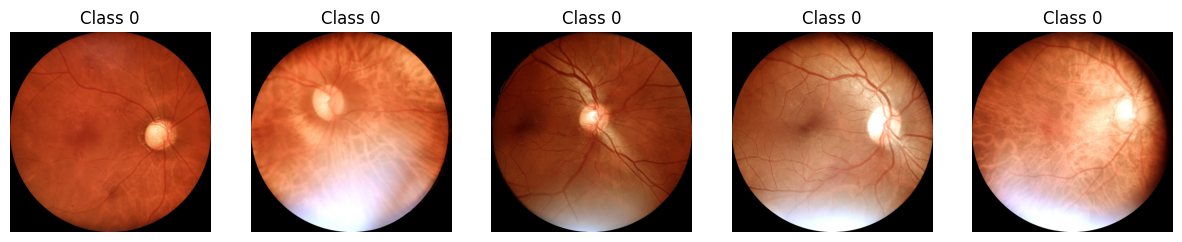

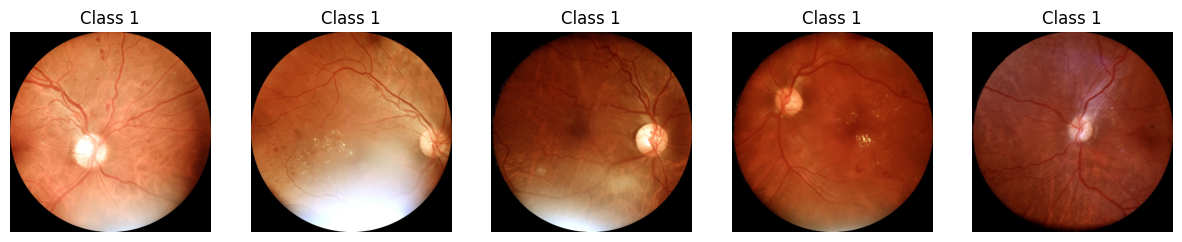

In [ ]:
import random
import matplotlib.pyplot as plt
from PIL import Image

def show_examples_per_class(x_paths, y_labels, class_id, n=5):
    # Select paths for this class
    paths = [p for p, y in zip(x_paths, y_labels) if y == class_id]

    if len(paths) == 0:
        print(f"No images found for class {class_id}")
        return

    # Choose n random samples
    sample_paths = random.sample(paths, min(n, len(paths)))

    plt.figure(figsize=(15, 3))
    for i, p in enumerate(sample_paths):
        img = Image.open(p).convert("RGB")
        plt.subplot(1, n, i + 1)
        plt.imshow(img)
        plt.title(f"Class {class_id}")
        plt.axis("off")
    plt.show()


#  Show samples for both classes (0 and 1)
for cls in [0, 1]:
    show_examples_per_class(x_train, y_train, class_id=cls, n=5)


In [ ]:
# !pip install -q pennylane pennylane-lightning tqdm imbalanced-learn


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [6]:
# ============================================================
# STANDALONE QSVM — COMMON SETUP
# ============================================================

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score,
    average_precision_score
)

import pennylane as qml

from collections import Counter
from tqdm.auto import tqdm

print("Libraries loaded.")

Libraries loaded.


In [7]:
# ============================================================
# FAST FIDELITY KERNEL HELPERS (GPU-accelerated, cu13)
# Mathematically identical to the pairwise kernel_fn approach:
# K[i,j] = |<psi(x_i)|psi(x_j)>|^2
# Instead of one circuit call per PAIR (O(n^2) circuit evals),
# we compute one statevector per SAMPLE (O(n) circuit evals),
# then get the whole kernel matrix from a single matmul.
# ============================================================

import torch

torch_device = "cuda" if torch.cuda.is_available() else "cpu"
print("Kernel compute device:", torch_device)


def build_statevector_fn(feature_map, n_qubits):
    dev = qml.device("default.qubit", wires=n_qubits)

    @qml.qnode(dev, interface="torch", diff_method=None)
    def circuit(x_batch):
        feature_map(x_batch)  # AngleEmbedding supports broadcasting
        return qml.state()

    return circuit


def compute_statevectors(X, feature_map, n_qubits, batch_size=512, desc="Statevectors"):
    circuit = build_statevector_fn(feature_map, n_qubits)
    X_t = torch.tensor(X, dtype=torch.float64)
    states = []
    with torch.no_grad():
        for i in tqdm(range(0, len(X_t), batch_size), desc=desc):
            batch = X_t[i:i + batch_size]
            s = circuit(batch)  # (batch, 2**n_qubits), complex
            states.append(s.to(torch_device))
    return torch.cat(states, dim=0)


def fidelity_kernel_matrix(states1, states2):
    overlap = states1.conj() @ states2.T
    return (overlap.abs() ** 2).real.cpu().numpy().astype(np.float64)


Kernel compute device: cuda


In [ ]:
# ============================================================
# RESNET18 FEATURE EXTRACTION
# ============================================================

IMG_SIZE = 224

mean = [0.485, 0.456, 0.406]
std  = [0.229, 0.224, 0.225]

eval_transform = transforms.Compose([
    transforms.Resize(int(IMG_SIZE * 1.1)),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(mean, std),
])


class ImagePathDataset(Dataset):

    def __init__(self, paths, labels):
        self.paths = list(paths)
        self.labels = list(labels)

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, idx):

        img = Image.open(
            self.paths[idx]
        ).convert("RGB")

        img = eval_transform(img)

        return img, int(self.labels[idx])


device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)


# ------------------------------------------------------------
# ImageNet pretrained ResNet18
# ------------------------------------------------------------

resnet = resnet18(
    weights=ResNet18_Weights.DEFAULT
).to(device)

resnet.fc = nn.Identity()
resnet.eval()

for p in resnet.parameters():
    p.requires_grad = False


def extract_resnet_features(
    paths,
    labels,
    batch_size=64
):

    dataset = ImagePathDataset(
        paths,
        labels
    )

    loader = DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    features = []
    targets = []

    with torch.no_grad():

        for images, y in tqdm(
            loader,
            desc="ResNet18 features"
        ):

            images = images.to(device)

            f = resnet(images)

            features.append(
                f.cpu().numpy()
            )

            targets.extend(
                y.numpy()
            )

    return (
        np.vstack(features),
        np.asarray(targets)
    )


print("Extracting training features...")

X_train_full, y_train_full = extract_resnet_features(
    x_train,
    y_train
)

print("Extracting validation features...")

X_val, y_val_q = extract_resnet_features(
    x_val,
    y_val
)

print("Extracting test features...")

X_test, y_test_q = extract_resnet_features(
    x_test,
    y_test
)

print(
    "\nFeature shapes:",
    X_train_full.shape,
    X_val.shape,
    X_test.shape
)

print(
    "Training distribution:",
    Counter(y_train_full)
)

In [9]:
# ============================================================
# USE THE COMPLETE TRAINING SET FOR QSVM
# ============================================================

X_train_qsvm = X_train_full.copy()
y_train_qsvm = y_train_full.copy()

print("Using COMPLETE training set")
print("Training samples:", len(X_train_qsvm))
print("Feature shape:", X_train_qsvm.shape)
print("Class distribution:", Counter(y_train_qsvm))


Using COMPLETE training set
Training samples: 3428
Feature shape: (3428, 512)
Class distribution: Counter({0: 3129, 1: 299})


In [11]:
# ============================================================
# 4-QUBIT FEATURE PREPARATION
# ============================================================

N_QUBITS = 4

scaler_4 = StandardScaler()

Xtr_scaled_4 = scaler_4.fit_transform(
    X_train_qsvm
)

Xval_scaled_4 = scaler_4.transform(
    X_val
)

Xtest_scaled_4 = scaler_4.transform(
    X_test
)


pca_4 = PCA(
    n_components=N_QUBITS,
    random_state=42
)

Xtr_4 = pca_4.fit_transform(
    Xtr_scaled_4
)

Xval_4 = pca_4.transform(
    Xval_scaled_4
)

Xtest_4 = pca_4.transform(
    Xtest_scaled_4
)

# ------------------------------------------------------------
# Scale PCA output into [-pi, pi] before angle embedding.
# AngleEmbedding uses each value as a literal RY rotation angle,
# which is periodic mod 2*pi — unscaled PCA components (often
# far outside [-pi, pi]) wrap around and make different samples
# collapse onto near-identical quantum states, producing an
# uninformative kernel. Fit only on train.
# ------------------------------------------------------------

from sklearn.preprocessing import MinMaxScaler

angle_scaler_4 = MinMaxScaler(feature_range=(-np.pi, np.pi))

Xtr_4   = angle_scaler_4.fit_transform(Xtr_4)
Xval_4  = angle_scaler_4.transform(Xval_4)
Xtest_4 = angle_scaler_4.transform(Xtest_4)

print(
    "4-qubit shapes:",
    Xtr_4.shape,
    Xval_4.shape,
    Xtest_4.shape
)

print(
    "4-qubit explained variance:",
    pca_4.explained_variance_ratio_.sum()
)

print(
    "4-qubit angle range after scaling:",
    Xtr_4.min(), "to", Xtr_4.max()
)

# ============================================================
# CLEAN 4-QUBIT FIDELITY QUANTUM KERNEL
# ============================================================

qdev_4 = qml.device(
    "default.qubit",
    wires=4
)


def feature_map_4(x):

    qml.AngleEmbedding(
        x,
        wires=range(4),
        rotation="Y"
    )

    # Ring entanglement (chain + wrap-around edge) instead of a plain
    # linear chain — richer mixing between all qubit pairs, same
    # fixed fidelity-kernel circuit, no trainable parameters added.
    for i in range(3):
        qml.CNOT(
            wires=[i, i + 1]
        )
    qml.CNOT(wires=[3, 0])


@qml.qnode(qdev_4)
def kernel_circuit_4(x1, x2):

    feature_map_4(x1)

    qml.adjoint(
        feature_map_4
    )(x2)

    return qml.probs(
        wires=range(4)
    )


def quantum_kernel_4(x1, x2):

    probs = kernel_circuit_4(
        x1,
        x2
    )

    # Probability of |0000>
    return float(
        np.real(probs[0])
    )

4-qubit shapes: (3428, 4) (490, 4) (980, 4)
4-qubit explained variance: 0.32705954
4-qubit angle range after scaling: -3.1415927 to 3.141593


In [ ]:
# ============================================================
# QUANTUM KERNEL MATRIX — FULL TRAINING SET (fast statevector method)
# Same kernel definition (fidelity: |<psi(x1)|psi(x2)>|^2), computed
# via O(n) statevectors + one matmul instead of O(n^2) circuit calls.
# ============================================================

print("Computing 4-qubit statevectors...")

S_train_4 = compute_statevectors(Xtr_4, feature_map_4, 4, desc="4-qubit train states")
S_val_4   = compute_statevectors(Xval_4, feature_map_4, 4, desc="4-qubit val states")
S_test_4  = compute_statevectors(Xtest_4, feature_map_4, 4, desc="4-qubit test states")

print("Computing 4-qubit training kernel...")
K_train_4 = fidelity_kernel_matrix(S_train_4, S_train_4)

print("Computing 4-qubit validation kernel...")
K_val_4 = fidelity_kernel_matrix(S_val_4, S_train_4)

print("Computing 4-qubit test kernel...")
K_test_4 = fidelity_kernel_matrix(S_test_4, S_train_4)

print(
    K_train_4.shape,
    K_val_4.shape,
    K_test_4.shape
)


In [ ]:
# ============================================================
# TRAIN STANDALONE 4-QUBIT QSVM
# ============================================================

qsvm_4 = SVC(
    kernel="precomputed",
    C=5,
    class_weight="balanced",
    probability=True
)

print("Training standalone 4-qubit QSVM...")

qsvm_4.fit(
    K_train_4,
    y_train_qsvm
)

print(" QSVM-4 trained")



# ============================================================
# EVALUATE 4-QUBIT QSVM
# ============================================================

val_pred_4 = qsvm_4.predict(K_val_4)
test_pred_4 = qsvm_4.predict(K_test_4)

val_prob_4 = qsvm_4.predict_proba(K_val_4)[:, 1]
test_prob_4 = qsvm_4.predict_proba(K_test_4)[:, 1]

print("\n========== QSVM-4 ==========")

print(
    "VAL Accuracy:",
    accuracy_score(y_val_q, val_pred_4)
)

val_auc = roc_auc_score(y_val_q, val_prob_4)
print(
    "VAL ROC-AUC:",
    val_auc
)

print(
    "VAL PR-AUC:",
    average_precision_score(y_val_q, val_prob_4)
)

print("\nTEST")

print(
    "Test Accuracy:",
    accuracy_score(y_test_q, test_pred_4)
)

test_auc = roc_auc_score(y_test_q, test_prob_4)
print(
    "Test ROC-AUC:",
    test_auc
)

print(
    "Test PR-AUC:",
    average_precision_score(y_test_q, test_prob_4)
)

print(
    classification_report(
        y_test_q,
        test_pred_4,
        digits=4
    )
)

print(
    "Confusion Matrix:\n",
    confusion_matrix(
        y_test_q,
        test_pred_4
    )
)

Training standalone 4-qubit QSVM...
✅ QSVM-4 trained

========== QSVM-4 ==========
VAL Accuracy: 0.5795918367346938
VAL ROC-AUC: 0.6339940689870455
VAL PR-AUC: 0.14499023746644746

TEST
Test Accuracy: 0.5795918367346938
Test ROC-AUC: 0.6315346697338152
Test PR-AUC: 0.12925304970819912
              precision    recall  f1-score   support

           0     0.9399    0.5765    0.7147       895
           1     0.1206    0.6118    0.2016        85

    accuracy                         0.5796       980
   macro avg     0.5303    0.5942    0.4581       980
weighted avg     0.8688    0.5796    0.6702       980

Confusion Matrix:
 [[516 379]
 [ 33  52]]


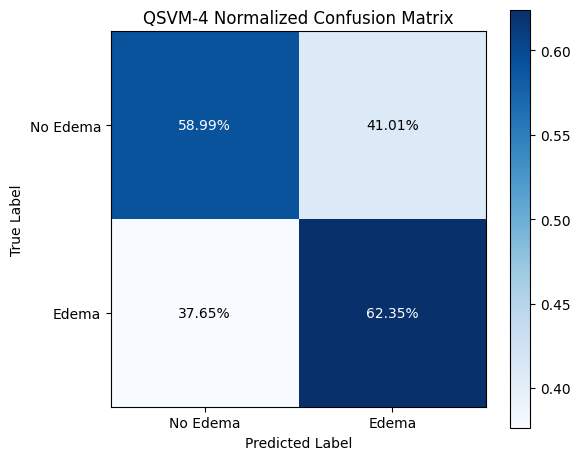

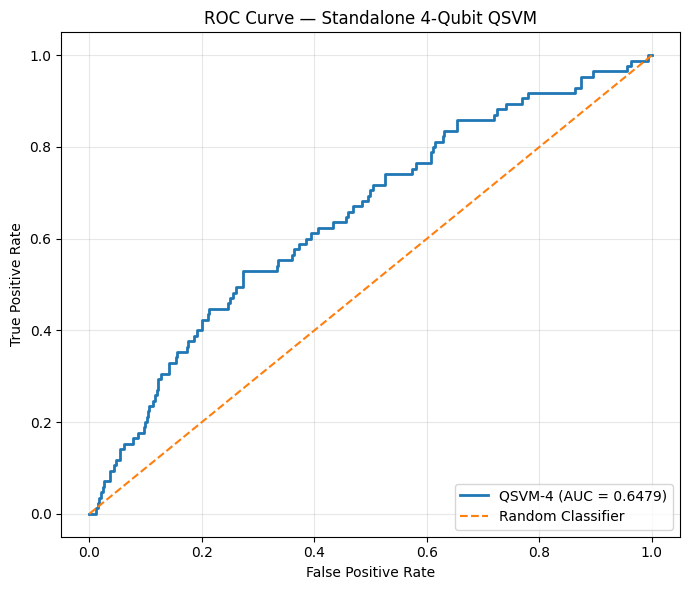

In [14]:
# ============================================================
# EVALUATE 4-QUBIT QSVM
# ============================================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve

# ============================================================
# NORMALIZED CONFUSION MATRIX
# ============================================================

cm = confusion_matrix(
    y_test_q,
    test_pred_4
)

# Normalize row-wise
cm_normalized = cm.astype(float) / cm.sum(
    axis=1,
    keepdims=True
)

plt.figure(figsize=(6, 5))

plt.imshow(
    cm_normalized,
    interpolation="nearest",
    cmap="Blues"
)

plt.title("QSVM-4 Normalized Confusion Matrix")
plt.colorbar()

classes = ["No Edema", "Edema"]

plt.xticks(
    np.arange(len(classes)),
    classes,
    rotation=0
)

plt.yticks(
    np.arange(len(classes)),
    classes
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")

# Add percentages
for i in range(cm_normalized.shape[0]):
    for j in range(cm_normalized.shape[1]):

        plt.text(
            j,
            i,
            f"{cm_normalized[i, j]:.2%}",
            ha="center",
            va="center",
            color="white"
            if cm_normalized[i, j] > 0.5
            else "black"
        )

plt.tight_layout()
plt.show()


# ============================================================
# ROC CURVE
# ============================================================

fpr, tpr, thresholds = roc_curve(
    y_test_q,
    test_prob_4
)

plt.figure(figsize=(7, 6))

plt.plot(
    fpr,
    tpr,
    linewidth=2,
    label=f"QSVM-4 (AUC = {test_auc:.4f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve — Standalone 4-Qubit QSVM")

plt.legend(
    loc="lower right"
)

plt.grid(
    alpha=0.3
)

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# 8-QUBIT FEATURE PREPARATION
# ============================================================

N_QUBITS = 8

scaler_8 = StandardScaler()

Xtr_scaled_8 = scaler_8.fit_transform(
    X_train_qsvm
)

Xval_scaled_8 = scaler_8.transform(
    X_val
)

Xtest_scaled_8 = scaler_8.transform(
    X_test
)


pca_8 = PCA(
    n_components=8,
    random_state=42
)

Xtr_8 = pca_8.fit_transform(
    Xtr_scaled_8
)

Xval_8 = pca_8.transform(
    Xval_scaled_8
)

Xtest_8 = pca_8.transform(
    Xtest_scaled_8
)

# ------------------------------------------------------------
# Scale PCA output into [-pi, pi] before angle embedding (same
# reasoning as the 4-qubit block above). Fit only on train.
# ------------------------------------------------------------

from sklearn.preprocessing import MinMaxScaler

angle_scaler_8 = MinMaxScaler(feature_range=(-np.pi, np.pi))

Xtr_8   = angle_scaler_8.fit_transform(Xtr_8)
Xval_8  = angle_scaler_8.transform(Xval_8)
Xtest_8 = angle_scaler_8.transform(Xtest_8)

print(
    "8-qubit shapes:",
    Xtr_8.shape,
    Xval_8.shape,
    Xtest_8.shape
)

print(
    "8-qubit explained variance:",
    pca_8.explained_variance_ratio_.sum()
)

print(
    "8-qubit angle range after scaling:",
    Xtr_8.min(), "to", Xtr_8.max()
)

# ============================================================
# 8-QUBIT FIDELITY QUANTUM KERNEL
# ============================================================

qdev_8 = qml.device(
    "default.qubit",
    wires=8
)


def feature_map_8(x):

    qml.AngleEmbedding(
        x,
        wires=range(8),
        rotation="Y"
    )

    # Ring entanglement (chain + wrap-around edge) instead of a plain
    # linear chain — richer mixing between all qubit pairs, same
    # fixed fidelity-kernel circuit, no trainable parameters added.
    for i in range(7):
        qml.CNOT(
            wires=[i, i + 1]
        )
    qml.CNOT(wires=[7, 0])


@qml.qnode(qdev_8)
def kernel_circuit_8(x1, x2):

    feature_map_8(x1)

    qml.adjoint(
        feature_map_8
    )(x2)

    return qml.probs(
        wires=range(8)
    )


def quantum_kernel_8(x1, x2):

    probs = kernel_circuit_8(
        x1,
        x2
    )

    return float(
        np.real(probs[0])
    )

8-qubit shapes: (3428, 8) (490, 8) (980, 8)
8-qubit explained variance: 0.4413469
8-qubit angle range after scaling: -3.1415927 to 3.141593


In [11]:
# ============================================================
# COMPUTE 8-QUBIT KERNEL MATRICES (fast statevector method)
# Same kernel definition as before, computed via O(n) statevectors
# + one matmul instead of O(n^2) circuit calls.
# ============================================================

print("Computing 8-qubit statevectors...")

S_train_8 = compute_statevectors(Xtr_8, feature_map_8, 8, desc="8-qubit train states")
S_val_8   = compute_statevectors(Xval_8, feature_map_8, 8, desc="8-qubit val states")
S_test_8  = compute_statevectors(Xtest_8, feature_map_8, 8, desc="8-qubit test states")

print("Computing 8-qubit training kernel...")
K_train_8 = fidelity_kernel_matrix(S_train_8, S_train_8)

print("Computing 8-qubit validation kernel...")
K_val_8 = fidelity_kernel_matrix(S_val_8, S_train_8)

print("Computing 8-qubit test kernel...")
K_test_8 = fidelity_kernel_matrix(S_test_8, S_train_8)

print(
    K_train_8.shape,
    K_val_8.shape,
    K_test_8.shape
)

# ============================================================
# TRAIN STANDALONE 8-QUBIT QSVM — MULTI-SEED, C-SEARCH
# Trains across seeds (42, 123, 456) x a C grid. `random_state`
# on SVC only affects the internal CV used by probability=True
# calibration (Platt scaling), since the kernel itself is fixed/
# precomputed — so this is exactly what varying "seed" can do
# here. Model selection is by VALIDATION PR-AUC (better signal
# than accuracy/ROC-AUC on this ~10.5:1 imbalanced dataset),
# ties broken by ROC-AUC. Best model becomes `qsvm_8` so cells
# below (evaluation + plots) run unchanged.
# ============================================================

SEEDS_8 = [42, 123, 456]
C_GRID_8 = [1, 2, 5, 10, 20, 50]

results_8 = []
best_score_8 = -np.inf
best_model_8 = None
best_cfg_8 = None

for seed in SEEDS_8:
    for C in C_GRID_8:

        model = SVC(
            kernel="precomputed",
            C=C,
            class_weight="balanced",
            probability=True,
            random_state=seed
        )

        model.fit(K_train_8, y_train_qsvm)

        v_pred = model.predict(K_val_8)
        v_prob = model.predict_proba(K_val_8)[:, 1]

        v_acc = accuracy_score(y_val_q, v_pred)
        v_auc = roc_auc_score(y_val_q, v_prob)
        v_pr_auc = average_precision_score(y_val_q, v_prob)

        results_8.append({
            "seed": seed,
            "C": C,
            "val_acc": v_acc,
            "val_roc_auc": v_auc,
            "val_pr_auc": v_pr_auc
        })

        print(f"seed={seed:>4} | C={C:>3} | val_acc={v_acc:.4f} | "
              f"val_ROC-AUC={v_auc:.4f} | val_PR-AUC={v_pr_auc:.4f}")

        score = (v_pr_auc, v_auc)
        if score > (best_score_8 if isinstance(best_score_8, tuple) else (best_score_8, best_score_8)):
            best_score_8 = score
            best_model_8 = model
            best_cfg_8 = (seed, C)

results_df_8 = pd.DataFrame(results_8).sort_values(
    ["val_pr_auc", "val_roc_auc"], ascending=False
).reset_index(drop=True)

print("\nTop 5 (seed, C) combos by validation PR-AUC:")
print(results_df_8.head(5).to_string(index=False))

print(f"\n✅ Best config: seed={best_cfg_8[0]}, C={best_cfg_8[1]} "
      f"(val PR-AUC={best_score_8[0]:.4f}, val ROC-AUC={best_score_8[1]:.4f})")

qsvm_8 = best_model_8

print("✅ QSVM-8 trained (best of seeds x C grid)")


Computing 8-qubit statevectors...


8-qubit train states:   0%|          | 0/7 [00:00<?, ?it/s]

8-qubit val states:   0%|          | 0/1 [00:00<?, ?it/s]

8-qubit test states:   0%|          | 0/2 [00:00<?, ?it/s]

Computing 8-qubit training kernel...
Computing 8-qubit validation kernel...
Computing 8-qubit test kernel...
(3428, 3428) (490, 3428) (980, 3428)
seed=  42 | C=  1 | val_acc=0.7612 | val_ROC-AUC=0.7264 | val_PR-AUC=0.2518
seed=  42 | C=  2 | val_acc=0.7571 | val_ROC-AUC=0.7135 | val_PR-AUC=0.2317
seed=  42 | C=  5 | val_acc=0.7776 | val_ROC-AUC=0.6993 | val_PR-AUC=0.2002
seed=  42 | C= 10 | val_acc=0.7959 | val_ROC-AUC=0.6797 | val_PR-AUC=0.1823
seed=  42 | C= 20 | val_acc=0.8061 | val_ROC-AUC=0.6660 | val_PR-AUC=0.1693
seed=  42 | C= 50 | val_acc=0.8286 | val_ROC-AUC=0.6563 | val_PR-AUC=0.1677
seed= 123 | C=  1 | val_acc=0.7612 | val_ROC-AUC=0.7265 | val_PR-AUC=0.2518
seed= 123 | C=  2 | val_acc=0.7571 | val_ROC-AUC=0.7138 | val_PR-AUC=0.2318
seed= 123 | C=  5 | val_acc=0.7776 | val_ROC-AUC=0.6991 | val_PR-AUC=0.2001
seed= 123 | C= 10 | val_acc=0.7959 | val_ROC-AUC=0.6795 | val_PR-AUC=0.1823
seed= 123 | C= 20 | val_acc=0.8061 | val_ROC-AUC=0.6654 | val_PR-AUC=0.1693
seed= 123 | C= 50 

In [14]:
# ============================================================
# BEST ACCURACY PER SEED — 8-QUBIT QSVM
# Summarizes, for each seed, the (C, accuracy) that gave the
# highest VALIDATION accuracy, then refits that best-per-seed
# config on train and reports its TEST accuracy too. Uses
# `results_8` from the sweep above — no retraining needed for
# the validation side.
# ============================================================

best_per_seed = (
    results_df_8
    .sort_values("val_acc", ascending=False)
    .groupby("seed", as_index=False)
    .first()
    .sort_values("seed")
)

print("Best config per seed (by validation accuracy):")
print(best_per_seed[["seed", "C", "val_acc", "val_roc_auc", "val_pr_auc"]].to_string(index=False))

print("\nRefitting best-per-seed models to report TEST accuracy...\n")

per_seed_test_results = []

for _, row in best_per_seed.iterrows():
    seed = int(row["seed"])
    C = row["C"]

    m = SVC(
        kernel="precomputed",
        C=C,
        class_weight="balanced",
        probability=True,
        random_state=seed
    )
    m.fit(K_train_8, y_train_qsvm)

    t_pred = m.predict(K_test_8)
    t_acc = accuracy_score(y_test_q, t_pred)

    per_seed_test_results.append({
        "seed": seed,
        "C": C,
        "val_acc": row["val_acc"],
        "test_acc": t_acc
    })

    print(f"seed={seed:>4} | C={C:>3} | val_acc={row['val_acc']:.4f} | test_acc={t_acc:.4f}")

per_seed_test_df = pd.DataFrame(per_seed_test_results)

best_overall_row = per_seed_test_df.loc[per_seed_test_df["test_acc"].idxmax()]

print(f"\n🏆 Best TEST accuracy: {best_overall_row['test_acc']:.4f} "
      f"(seed={int(best_overall_row['seed'])}, C={best_overall_row['C']})")


Best config per seed (by validation accuracy):
 seed  C  val_acc  val_roc_auc  val_pr_auc
   42 50 0.828571     0.656261    0.167736
  123 50 0.828571     0.656417    0.167755
  456 50 0.828571     0.656261    0.167736

Refitting best-per-seed models to report TEST accuracy...

seed=  42 | C=50.0 | val_acc=0.8286 | test_acc=0.8286
seed= 123 | C=50.0 | val_acc=0.8286 | test_acc=0.8286
seed= 456 | C=50.0 | val_acc=0.8286 | test_acc=0.8286

🏆 Best TEST accuracy: 0.8286 (seed=42, C=50.0)


In [15]:
# ============================================================
# CLASSIFICATION REPORT — BEST ACCURACY CONFIGURATION
# 8-QUBIT QSVM — EACH SEED
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    accuracy_score
)

print("=" * 80)
print("8-QUBIT QSVM — BEST VALIDATION-ACCURACY CONFIGURATION PER SEED")
print("=" * 80)

for _, row in best_per_seed.iterrows():

    seed = int(row["seed"])
    C = row["C"]

    # --------------------------------------------------------
    # Refit best configuration for this seed
    # --------------------------------------------------------

    m = SVC(
        kernel="precomputed",
        C=C,
        class_weight="balanced",
        probability=True,
        random_state=seed
    )

    m.fit(
        K_train_8,
        y_train_qsvm
    )

    # --------------------------------------------------------
    # Test predictions
    # --------------------------------------------------------

    y_pred = m.predict(
        K_test_8
    )

    test_acc = accuracy_score(
        y_test_q,
        y_pred
    )

    # --------------------------------------------------------
    # Classification report
    # --------------------------------------------------------

    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    print(
        f"Best C: {C}"
    )

    print(
        f"Validation Accuracy: {row['val_acc']:.4f}"
    )

    print(
        f"Test Accuracy:       {test_acc:.4f}"
    )

    print("\nClassification Report:")

    print(
        classification_report(
            y_test_q,
            y_pred,
            digits=4
        )
    )

8-QUBIT QSVM — BEST VALIDATION-ACCURACY CONFIGURATION PER SEED

SEED 42
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy:       0.8286

Classification Report:
              precision    recall  f1-score   support

           0     0.9364    0.8715    0.9028       895
           1     0.2177    0.3765    0.2759        85

    accuracy                         0.8286       980
   macro avg     0.5770    0.6240    0.5893       980
weighted avg     0.8740    0.8286    0.8484       980


SEED 123
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy:       0.8286

Classification Report:
              precision    recall  f1-score   support

           0     0.9364    0.8715    0.9028       895
           1     0.2177    0.3765    0.2759        85

    accuracy                         0.8286       980
   macro avg     0.5770    0.6240    0.5893       980
weighted avg     0.8740    0.8286    0.8484       980


SEED 456
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy:       0.8286

In [19]:
# ============================================================
# 8-QUBIT QSVM — BEST CONFIGURATION PER SEED
# CLASSIFICATION REPORT + MEAN ± SD
#
# Metrics:
#   Accuracy
#   Macro F1
#   Weighted F1
#   Weighted Precision
#   Weighted Recall
# ============================================================

from sklearn.svm import SVC
from sklearn.metrics import (
    classification_report,
    accuracy_score
)
import numpy as np
import pandas as pd

all_results = []

print("=" * 80)
print("8-QUBIT QSVM — CLASSIFICATION REPORTS")
print("=" * 80)

for _, row in best_per_seed.iterrows():

    seed = int(row["seed"])
    C = row["C"]

    # --------------------------------------------------------
    # Refit best configuration for this seed
    # --------------------------------------------------------

    model = SVC(
        kernel="precomputed",
        C=C,
        class_weight="balanced",
        probability=True,
        random_state=seed
    )

    model.fit(
        K_train_8,
        y_train_qsvm
    )

    # --------------------------------------------------------
    # Test predictions
    # --------------------------------------------------------

    y_pred = model.predict(
        K_test_8
    )

    # --------------------------------------------------------
    # Classification report as dictionary
    # --------------------------------------------------------

    report = classification_report(
        y_test_q,
        y_pred,
        output_dict=True,
        zero_division=0
    )

    # --------------------------------------------------------
    # Extract metrics
    # --------------------------------------------------------

    accuracy = accuracy_score(
        y_test_q,
        y_pred
    )

    macro_f1 = report["macro avg"]["f1-score"]

    weighted_f1 = report["weighted avg"]["f1-score"]

    weighted_precision = report["weighted avg"]["precision"]

    weighted_recall = report["weighted avg"]["recall"]

    # --------------------------------------------------------
    # Store
    # --------------------------------------------------------

    all_results.append({
        "seed": seed,
        "C": C,
        "accuracy": accuracy,
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,
        "weighted_precision": weighted_precision,
        "weighted_recall": weighted_recall
    })

    # --------------------------------------------------------
    # Print classification report
    # --------------------------------------------------------

    print("\n" + "=" * 80)
    print(f"SEED {seed}")
    print("=" * 80)

    print(
        f"Best C: {C}"
    )

    print(
        f"Validation Accuracy: {row['val_acc']:.4f}"
    )

    print(
        f"Test Accuracy: {accuracy:.4f}"
    )

    print("\nClassification Report:\n")

    print(
        classification_report(
            y_test_q,
            y_pred,
            digits=4,
            zero_division=0
        )
    )


# ============================================================
# CREATE RESULTS DATAFRAME
# ============================================================

qsvm_metrics_df = pd.DataFrame(
    all_results
)

print("\n" + "=" * 80)
print("PER-SEED SUMMARY")
print("=" * 80)

print(
    qsvm_metrics_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.4f}"
    )
)


# ============================================================
# MEAN ± SD
# ============================================================

metrics = [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "weighted_precision",
    "weighted_recall"
]

summary = []

for metric in metrics:

    mean = qsvm_metrics_df[metric].mean()

    sd = qsvm_metrics_df[metric].std(
        ddof=1
    )

    summary.append({
        "Metric": metric,
        "Mean": mean,
        "SD": sd,
        "Mean ± SD": f"{mean:.4f} ± {sd:.4f}"
    })


summary_df = pd.DataFrame(
    summary
)

# ============================================================
# PRINT FINAL MEAN ± SD
# ============================================================

print("\n" + "=" * 80)
print("8-QUBIT QSVM — MEAN ± SD ACROSS SEEDS")
print("=" * 80)

for _, row in summary_df.iterrows():

    print(
        f"{row['Metric']:<22} "
        f"{row['Mean ± SD']}"
    )

8-QUBIT QSVM — CLASSIFICATION REPORTS

SEED 42
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy: 0.8286

Classification Report:

              precision    recall  f1-score   support

           0     0.9364    0.8715    0.9028       895
           1     0.2177    0.3765    0.2759        85

    accuracy                         0.8286       980
   macro avg     0.5770    0.6240    0.5893       980
weighted avg     0.8740    0.8286    0.8484       980


SEED 123
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy: 0.8286

Classification Report:

              precision    recall  f1-score   support

           0     0.9364    0.8715    0.9028       895
           1     0.2177    0.3765    0.2759        85

    accuracy                         0.8286       980
   macro avg     0.5770    0.6240    0.5893       980
weighted avg     0.8740    0.8286    0.8484       980


SEED 456
Best C: 50.0
Validation Accuracy: 0.8286
Test Accuracy: 0.8286

Classification Report:

              p